# 03 · Customer exploration
Who the subscribers are, and how spend is distributed.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
cs = query(engine, "SELECT * FROM telco.v_customer_summary")
for c in ["avg_monthly_revenue", "revenue", "early_monthly_revenue", "avg_data_mb", "avg_voice_minutes"]:
    cs[c] = cs[c].astype(float)
cs.groupby("customer_type").avg_monthly_revenue.describe(percentiles=[.25, .5, .75, .95])

,count,mean,std,min,25%,50%,75%,95%,max
customer_type,,,,,,,,,
Postpaid,"3,403.00","1,899.34","1,274.17",16.60,642.12,"2,113.15","2,891.82","3,913.27","5,806.00"
Prepaid,"25,093.00",523.63,367.25,0.00,241.00,530.53,704.41,993.54,"5,701.34"


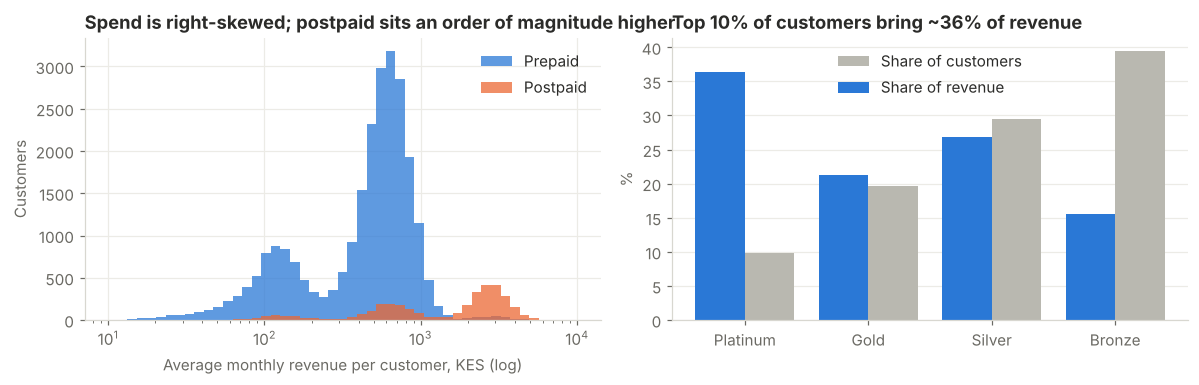

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for t, col in [("Prepaid", an.PRIMARY), ("Postpaid", an.HIGHLIGHT)]:
    d = cs[(cs.customer_type == t) & (cs.avg_monthly_revenue > 0)].avg_monthly_revenue
    ax[0].hist(d, bins=np.logspace(1, 4, 50), color=col, alpha=.75, label=t)
ax[0].set_xscale("log"); ax[0].set_xlabel("Average monthly revenue per customer, KES (log)"); ax[0].set_ylabel("Customers")
ax[0].set_title("Spend is right-skewed; postpaid sits an order of magnitude higher"); ax[0].legend()
v = o("q05_value_segments").query("value_segment != 'Unsegmented (too new)'")
ax[1].bar(v.value_segment.str.split(" ").str[0], v.customer_share_pct, color=an.CONTEXT, width=.4, label="Share of customers", align="edge")
ax[1].bar(v.value_segment.str.split(" ").str[0], v.revenue_share_pct, color=an.PRIMARY, width=-.4, label="Share of revenue", align="edge")
ax[1].set_ylabel("%"); ax[1].set_title("Top 10% of customers bring ~36% of revenue"); ax[1].legend(); ax[1].grid(axis="x", visible=False)
fig.tight_layout(); an.save(fig, "spend_distribution_and_value_concentration");

In [4]:
o('q05_value_segments')

,value_segment,customers,customer_share_pct,revenue_kes,revenue_share_pct,avg_monthly_revenue_kes,churned_pct,postpaid_pct
0,Platinum (top 10%),2807,9.90,"165,534,252.00",36.40,"2,464.00",8.50,72.20
1,Gold (next 20%),5613,19.70,"96,520,987.00",21.20,797.00,20.20,6.00
2,Silver (next 30%),8418,29.50,"121,871,190.00",26.80,596.00,23.80,5.10
3,Unsegmented (too new),434,1.50,"240,528.00",0.10,554.00,0.00,11.10
4,Bronze (bottom 40%),11224,39.40,"70,830,430.00",15.60,264.00,42.60,5.00


Value segments are deciles of **early** monthly revenue: the first three full months we observe each customer. A segment based on *lifetime* average revenue would be circular, because customers on their way out spend less, so churners would be labelled low-value *because* they churned. Using early behaviour, the segment is something the business could have known in advance.

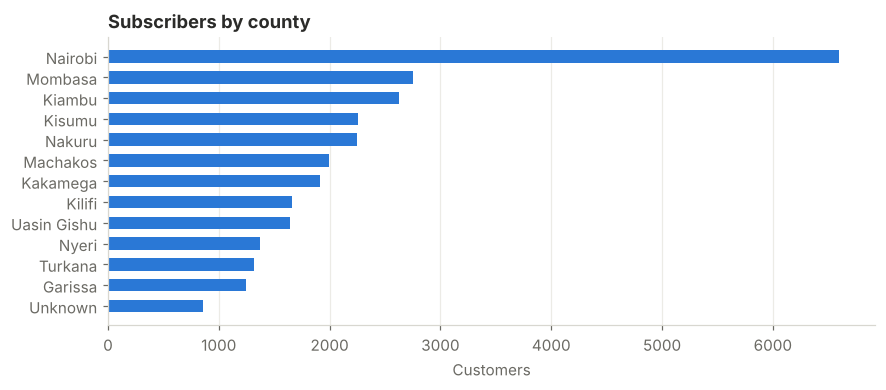

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
cnt = cs.groupby(["county"]).size().sort_values()
ax.barh(cnt.index, cnt.values, color=an.PRIMARY, height=.6); ax.set_xlabel("Customers"); ax.set_title("Subscribers by county")
ax.grid(axis="y", visible=False); an.save(fig, "customers_by_county");

In [6]:
pd.crosstab(cs.age_group, cs.customer_type, normalize='columns').mul(100).round(1)

customer_type,Postpaid,Prepaid
age_group,,
18-24,10.80,24.20
25-34,28.80,28.70
35-44,31.40,20.70
45-54,20.10,15.60
55+,8.90,10.80
